# SAMS Vibration — UCI Accelerometer (NORMAL / ABNORMAL)

Train and compare **vibration classifiers** for machine-state monitoring using the
[UCI Accelerometer](https://archive.ics.uci.edu/dataset/846/accelerometer) dataset.

## Goals
- Load & inspect the UCI Accelerometer data first (do not train on raw rows blindly)
- Map vibration configs to a **binary machine-state** label (`NORMAL` / `ABNORMAL`)
- Build **sliding windows** → extract time/frequency features
- Run **≥ 4 experiments** with different approaches
- Save **model + metadata** to Drive
- Compare with **Accuracy, Precision, Recall, F1**

## Label map (SAMS experiment 1)
| Original | SAMS meaning |
|----------|--------------|
| `wconfid = 1` | NORMAL vibration |
| `wconfid = 2` | ABNORMAL vibration |
| `wconfid = 3` | ABNORMAL vibration |


## Experiment plan
| # | Approach | Model | Input |
|---|----------|-------|-------|
| 1 | Classical baseline | Random Forest | Handcrafted window features |
| 2 | Boosted trees | XGBoost | Same features |
| 3 | Margin classifier | SVM (RBF) | Same features (scaled) |
| 4 | Deep learning | 1D CNN | Raw X/Y/Z windows |

## Pipeline
```text
Raw accelerometer → Sliding windows → Feature extraction / raw tensors
        → RF / XGBoost / SVM / 1D CNN → NORMAL / ABNORMAL → Compare
```

## Progression (later)
```text
UCI Accelerometer → Bosch CNC → Physical SAMS accelerometer → Deploy
```

## 0. Colab setup — directories, Drive, packages

In [1]:
# --- Colab environment -------------------------------------------------------
import os
from pathlib import Path

IN_COLAB = False
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

print("Running in Colab:", IN_COLAB)

SAMS_ROOT = Path("/content/SAMS") if IN_COLAB else Path("./SAMS_runtime")
for p in [
    SAMS_ROOT / "datasets" / "vibration" / "accelerometer",
    SAMS_ROOT / "datasets" / "vibration" / "bosch_cnc",
    SAMS_ROOT / "models",
    SAMS_ROOT / "notebooks",
    SAMS_ROOT / "results",
]:
    p.mkdir(parents=True, exist_ok=True)

print("SAMS_ROOT:", SAMS_ROOT.resolve())

Running in Colab: True
SAMS_ROOT: /content/SAMS


In [2]:
# --- Mount Google Drive (persist trained models / results) -------------------
DRIVE_ROOT = None

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_ROOT = Path("/content/drive/MyDrive/SAMS")
else:
    DRIVE_ROOT = Path("./SAMS_drive_mirror")

for p in [
    DRIVE_ROOT / "models" / "vibration",
    DRIVE_ROOT / "experiments",
    DRIVE_ROOT / "results" / "vibration",
    DRIVE_ROOT / "sams_dataset",
]:
    p.mkdir(parents=True, exist_ok=True)

MODELS_DIR = DRIVE_ROOT / "models" / "vibration"
RESULTS_DIR = DRIVE_ROOT / "results" / "vibration"
EXPERIMENTS_DIR = DRIVE_ROOT / "experiments"
DATA_DIR = SAMS_ROOT / "datasets" / "vibration" / "accelerometer"

print("DRIVE_ROOT:", DRIVE_ROOT)
print("MODELS_DIR:", MODELS_DIR)
print("RESULTS_DIR:", RESULTS_DIR)

Mounted at /content/drive
DRIVE_ROOT: /content/drive/MyDrive/SAMS
MODELS_DIR: /content/drive/MyDrive/SAMS/models/vibration
RESULTS_DIR: /content/drive/MyDrive/SAMS/results/vibration


In [3]:
# --- Install dependencies ----------------------------------------------------
import subprocess
import sys

pkgs = [
    "ucimlrepo",
    "scikit-learn",
    "scipy",
    "xgboost",
    "seaborn",
    "tqdm",
    "joblib",
]
if IN_COLAB:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *pkgs])
    print("Packages installed.")
else:
    print("Skipping pip install outside Colab (use your venv if needed).")
    print("Required:", ", ".join(pkgs))

Packages installed.


In [4]:
# --- Imports & reproducibility -----------------------------------------------
import gc
import json
import time
import warnings
from datetime import datetime, timezone
from typing import Any, Dict, List, Optional, Tuple

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from torch.utils.data import DataLoader, TensorDataset
from tqdm.auto import tqdm

warnings.filterwarnings("ignore", category=UserWarning)

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

CLASS_NAMES = ["NORMAL", "ABNORMAL"]
LABEL_TO_IDX = {"NORMAL": 0, "ABNORMAL": 1}

# Sampling: one sample every 20 ms → 50 Hz
SAMPLE_PERIOD_MS = 20
SAMPLE_RATE_HZ = 1000 / SAMPLE_PERIOD_MS  # 50.0
WINDOW_SIZE = 100   # 2.0 seconds
WINDOW_STRIDE = 50  # 1.0 second step (50% overlap)

print(f"fs={SAMPLE_RATE_HZ} Hz | window={WINDOW_SIZE} samples ({WINDOW_SIZE/SAMPLE_RATE_HZ:.1f}s) | stride={WINDOW_STRIDE}")

device: cuda
fs=50.0 Hz | window=100 samples (2.0s) | stride=50


## 1. Load UCI Accelerometer (id=846)

In [6]:
import pandas as pd
from pathlib import Path
import zipfile
import urllib.request

DATA_DIR = Path("/content/SAMS/datasets/vibration/accelerometer")
DATA_DIR.mkdir(parents=True, exist_ok=True)

zip_path = DATA_DIR / "accelerometer.zip"
csv_candidates = list(DATA_DIR.glob("*.csv"))

if not csv_candidates:
    url = "https://archive.ics.uci.edu/static/public/846/accelerometer.zip"
    urllib.request.urlretrieve(url, zip_path)
    with zipfile.ZipFile(zip_path, "r") as zf:
        zf.extractall(DATA_DIR)
    csv_candidates = list(DATA_DIR.glob("*.csv"))

csv_path = csv_candidates[0]
print("Using:", csv_path)

X = pd.read_csv(csv_path)
y = None  # labels are in X["wconfid"]

print(X.shape)
print(X.head())
print(X.columns.tolist())

Using: /content/SAMS/datasets/vibration/accelerometer/accelerometer (1).csv
(153000, 5)
   wconfid  pctid      x      y      z
0        1     20  1.004  0.090 -0.125
1        1     20  1.004 -0.043 -0.125
2        1     20  0.969  0.090 -0.121
3        1     20  0.973 -0.012 -0.137
4        1     20  1.000 -0.016 -0.121
['wconfid', 'pctid', 'x', 'y', 'z']


In [8]:
print("=== Columns / dtypes ===")
print(X.dtypes)

print("\n=== info() ===")
X.info()

print("\n=== describe() ===")
display(X.describe())

print("\nwconfid value counts:")
print(X["wconfid"].value_counts().sort_index())

print("\npctid value counts (fan speed %):")
print(X["pctid"].value_counts().sort_index())

=== Columns / dtypes ===
wconfid      int64
pctid        int64
x          float64
y          float64
z          float64
dtype: object

=== info() ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 153000 entries, 0 to 152999
Data columns (total 5 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   wconfid  153000 non-null  int64  
 1   pctid    153000 non-null  int64  
 2   x        153000 non-null  float64
 3   y        153000 non-null  float64
 4   z        153000 non-null  float64
dtypes: float64(3), int64(2)
memory usage: 5.8 MB

=== describe() ===


,wconfid,pctid,x,y,z
count,153000.000000,153000.000000,153000.000000,153000.000000,153000.000000
mean,2.000000,60.000000,0.995622,0.005351,-0.117769
std,0.816499,24.494977,0.773958,0.742602,0.517008
min,1.000000,20.000000,-8.000000,-8.000000,-5.867000
25%,1.000000,40.000000,0.945000,-0.078000,-0.172000
50%,2.000000,60.000000,0.992000,0.008000,-0.125000
75%,3.000000,80.000000,1.039000,0.105000,-0.066000
max,3.000000,100.000000,7.996000,7.996000,6.086000



wconfid value counts:
wconfid
1    51000
2    51000
3    51000
Name: count, dtype: int64

pctid value counts (fan speed %):
pctid
20     9000
25     9000
30     9000
35     9000
40     9000
45     9000
50     9000
55     9000
60     9000
65     9000
70     9000
75     9000
80     9000
85     9000
90     9000
95     9000
100    9000
Name: count, dtype: int64


## 2. SAMS binary labels + magnitude

In [9]:
df = X.copy()

# Preserve original order — UCI rows are sequential time within each (wconfid, pctid) run
df = df.reset_index(drop=True)
df["sample_idx"] = np.arange(len(df))

df["label"] = df["wconfid"].apply(lambda v: 0 if int(v) == 1 else 1)
df["label_name"] = df["label"].map({0: "NORMAL", 1: "ABNORMAL"})

df["magnitude"] = np.sqrt(df["x"] ** 2 + df["y"] ** 2 + df["z"] ** 2)

print(df["label_name"].value_counts())
display(df[["wconfid", "pctid", "x", "y", "z", "magnitude", "label_name"]].head())

print("\nMagnitude by label:")
display(df.groupby("label_name")["magnitude"].describe())

# Cache raw table locally (ephemeral in Colab)
raw_path = DATA_DIR / "uci_accelerometer_labeled.csv"
df.to_csv(raw_path, index=False)
print("Saved:", raw_path)

label_name
ABNORMAL    102000
NORMAL       51000
Name: count, dtype: int64


,wconfid,pctid,x,y,z,magnitude,label_name
0,1,20,1.004,0.090,-0.125,1.015747,NORMAL
1,1,20,1.004,-0.043,-0.125,1.012665,NORMAL
2,1,20,0.969,0.090,-0.121,0.980664,NORMAL
3,1,20,0.973,-0.012,-0.137,0.982671,NORMAL
4,1,20,1.000,-0.016,-0.121,1.007421,NORMAL



Magnitude by label:


,count,mean,std,min,25%,50%,75%,max
label_name,,,,,,,,
ABNORMAL,102000.0,1.173434,0.586234,0.049980,0.981669,1.013661,1.076945,9.721154
NORMAL,51000.0,1.569425,1.168101,0.054351,0.993750,1.048629,1.600649,10.153370


Saved: /content/SAMS/datasets/vibration/accelerometer/uci_accelerometer_labeled.csv


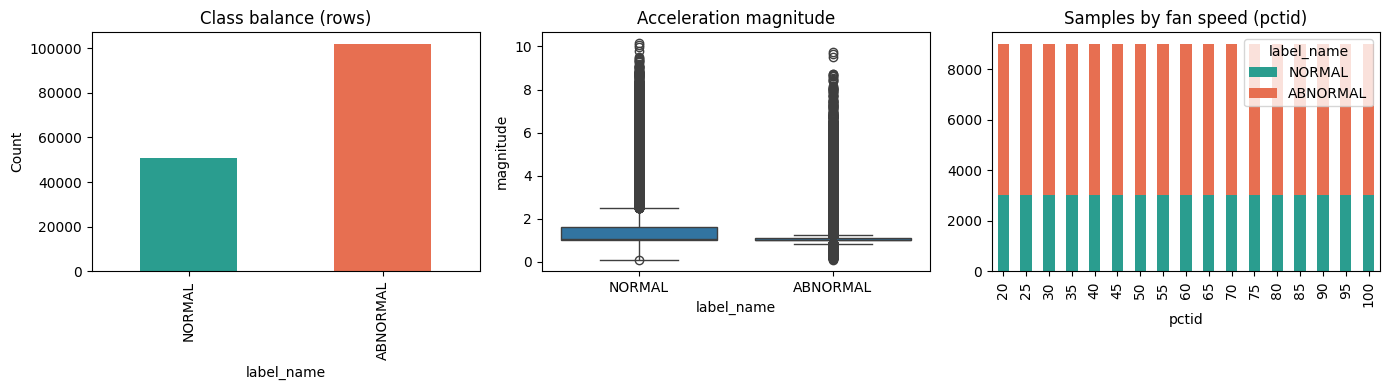

Saved: /content/drive/MyDrive/SAMS/results/vibration/eda/vibration_uci_eda_overview.png


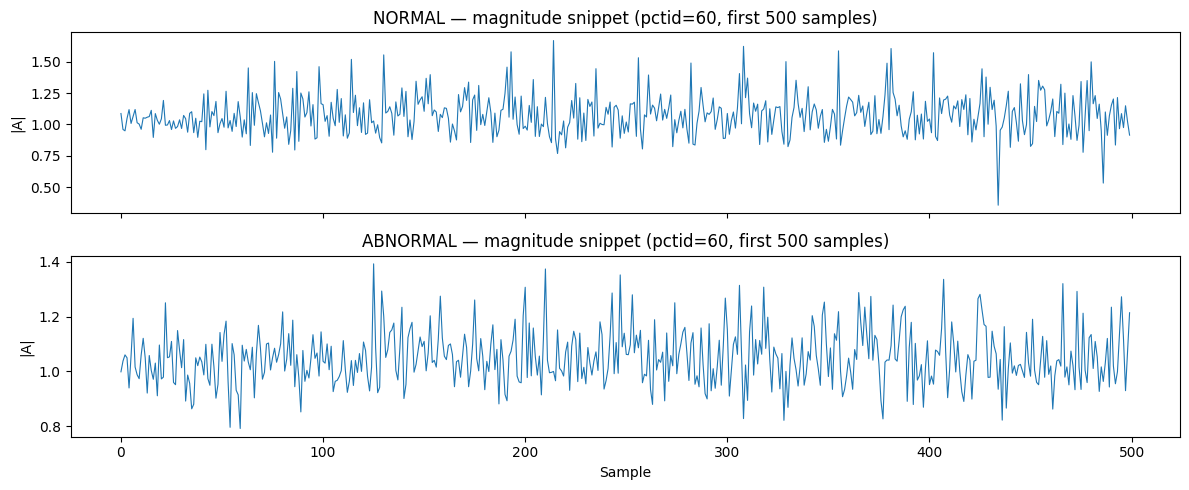

Saved: /content/drive/MyDrive/SAMS/results/vibration/eda/vibration_uci_magnitude_snippets.png


In [10]:
# --- EDA plots ---------------------------------------------------------------
eda_dir = RESULTS_DIR / "eda"
eda_dir.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

df["label_name"].value_counts().reindex(CLASS_NAMES).plot(
    kind="bar", ax=axes[0], color=["#2a9d8f", "#e76f51"]
)
axes[0].set_title("Class balance (rows)")
axes[0].set_ylabel("Count")

sns.boxplot(data=df, x="label_name", y="magnitude", order=CLASS_NAMES, ax=axes[1])
axes[1].set_title("Acceleration magnitude")

pivot = df.groupby(["pctid", "label_name"]).size().unstack(fill_value=0)
pivot.reindex(columns=CLASS_NAMES).plot(kind="bar", stacked=True, ax=axes[2],
                                        color=["#2a9d8f", "#e76f51"])
axes[2].set_title("Samples by fan speed (pctid)")
axes[2].set_xlabel("pctid")

plt.tight_layout()
fig_path = eda_dir / "vibration_uci_eda_overview.png"
plt.savefig(fig_path, dpi=140, bbox_inches="tight")
plt.show()
print("Saved:", fig_path)

# Short waveform snippet per class at a mid fan speed
demo_pct = sorted(df["pctid"].unique())[len(df["pctid"].unique()) // 2]
fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
for ax, name in zip(axes, CLASS_NAMES):
    sub = df[(df["label_name"] == name) & (df["pctid"] == demo_pct)].head(500)
    ax.plot(sub["magnitude"].values, lw=0.8)
    ax.set_ylabel("|A|")
    ax.set_title(f"{name} — magnitude snippet (pctid={demo_pct}, first 500 samples)")
axes[-1].set_xlabel("Sample")
plt.tight_layout()
fig_path2 = eda_dir / "vibration_uci_magnitude_snippets.png"
plt.savefig(fig_path2, dpi=140, bbox_inches="tight")
plt.show()
print("Saved:", fig_path2)

## 3. Sliding windows + feature extraction

A single XYZ sample is not a useful unit for SAMS. We slide fixed windows over each
`(wconfid, pctid)` run (contiguous time), extract classical stats, and keep the raw
window tensor for the 1D CNN.

**Split strategy:** hold out entire fan speeds (`pctid`) so the model must generalise
to unseen operating speeds — closer to deployment than a random row shuffle.

In [12]:
from scipy.stats import kurtosis, skew


def _axis_features(sig: np.ndarray, prefix: str) -> Dict[str, float]:
    """Handcrafted stats for one 1D signal."""
    sig = sig.astype(np.float64)
    rms = float(np.sqrt(np.mean(sig ** 2)))
    # Dominant frequency via FFT (exclude DC)
    n = len(sig)
    fft = np.fft.rfft(sig - sig.mean())
    freqs = np.fft.rfftfreq(n, d=1.0 / SAMPLE_RATE_HZ)
    mag = np.abs(fft)
    if len(mag) > 1:
        dom_idx = 1 + int(np.argmax(mag[1:]))
        dom_freq = float(freqs[dom_idx])
        dom_amp = float(mag[dom_idx])
    else:
        dom_freq, dom_amp = 0.0, 0.0

    return {
        f"{prefix}_mean": float(sig.mean()),
        f"{prefix}_std": float(sig.std()),
        f"{prefix}_rms": rms,
        f"{prefix}_max": float(sig.max()),
        f"{prefix}_min": float(sig.min()),
        f"{prefix}_ptp": float(np.ptp(sig)),  # NumPy 2.0+
        f"{prefix}_energy": float(np.sum(sig ** 2)),
        f"{prefix}_var": float(sig.var()),
        f"{prefix}_kurtosis": float(kurtosis(sig, fisher=True, bias=False)),
        f"{prefix}_skew": float(skew(sig, bias=False)),
        f"{prefix}_dom_freq": dom_freq,
        f"{prefix}_dom_amp": dom_amp,
    }


def build_windows(
    frame: pd.DataFrame,
    window_size: int = WINDOW_SIZE,
    stride: int = WINDOW_STRIDE,
) -> Tuple[pd.DataFrame, np.ndarray]:
    """Return feature table + raw windows array shaped (N, window, 3)."""
    feature_rows: List[Dict[str, Any]] = []
    raw_windows: List[np.ndarray] = []

    group_cols = ["wconfid", "pctid"]
    groups = frame.groupby(group_cols, sort=True)

    for (wconfid, pctid), g in tqdm(groups, desc="Windowing"):
        g = g.sort_values("sample_idx")
        xyz = g[["x", "y", "z"]].to_numpy(dtype=np.float32)
        labels = g["label"].to_numpy()
        n = len(g)
        if n < window_size:
            continue

        for start in range(0, n - window_size + 1, stride):
            end = start + window_size
            win = xyz[start:end]  # (W, 3)
            win_labels = labels[start:end]
            # Require a pure window (all same label) to avoid boundary noise
            if len(np.unique(win_labels)) != 1:
                continue
            label = int(win_labels[0])

            mag = np.sqrt(np.sum(win ** 2, axis=1))
            feats: Dict[str, Any] = {
                "wconfid": int(wconfid),
                "pctid": int(pctid),
                "start": int(start),
                "label": label,
                "label_name": CLASS_NAMES[label],
            }
            for i, axis in enumerate(["x", "y", "z"]):
                feats.update(_axis_features(win[:, i], axis))
            feats.update(_axis_features(mag, "mag"))

            feature_rows.append(feats)
            raw_windows.append(win)

    feat_df = pd.DataFrame(feature_rows)
    raw_arr = np.stack(raw_windows, axis=0) if raw_windows else np.empty((0, window_size, 3), dtype=np.float32)
    return feat_df, raw_arr


feat_df, raw_windows = build_windows(df)
print("Windows:", len(feat_df), "| raw shape:", raw_windows.shape)
print(feat_df["label_name"].value_counts())
display(feat_df.head())

FEATURE_COLS = [c for c in feat_df.columns if c not in {
    "wconfid", "pctid", "start", "label", "label_name"
}]
print(f"{len(FEATURE_COLS)} features:", FEATURE_COLS[:8], "...")

feat_path = DATA_DIR / "uci_window_features.csv"
feat_df.to_csv(feat_path, index=False)
np.save(DATA_DIR / "uci_raw_windows.npy", raw_windows)
print("Saved features →", feat_path)

Windowing:   0%|          | 0/51 [00:00<?, ?it/s]

Windows: 3009 | raw shape: (3009, 100, 3)
label_name
ABNORMAL    2006
NORMAL      1003
Name: count, dtype: int64


,wconfid,pctid,start,label,label_name,x_mean,x_std,x_rms,x_max,x_min,...,mag_rms,mag_max,mag_min,mag_ptp,mag_energy,mag_var,mag_kurtosis,mag_skew,mag_dom_freq,mag_dom_amp
0,1,20,0,0,NORMAL,0.99273,0.020690,0.992946,1.047,0.957,...,1.004534,1.053202,0.964794,0.088408,100.908881,0.000392,-0.447906,0.460499,16.5,0.592981
1,1,20,50,0,NORMAL,0.99416,0.021495,0.994392,1.047,0.957,...,1.006156,1.053202,0.964794,0.088408,101.234992,0.000420,-0.671674,0.338822,16.5,0.517780
2,1,20,100,0,NORMAL,0.99552,0.021300,0.995748,1.039,0.957,...,1.007745,1.052545,0.971435,0.081110,101.554952,0.000398,-0.856201,0.338484,16.5,0.600113
3,1,20,150,0,NORMAL,0.99387,0.022460,0.994124,1.039,0.953,...,1.006020,1.051451,0.969979,0.081473,101.207623,0.000444,-0.759131,0.440977,16.5,0.602518
4,1,20,200,0,NORMAL,0.99418,0.023330,0.994454,1.047,0.938,...,1.006182,1.060331,0.949354,0.110977,101.240223,0.000498,-0.427531,0.291774,17.5,0.553592


48 features: ['x_mean', 'x_std', 'x_rms', 'x_max', 'x_min', 'x_ptp', 'x_energy', 'x_var'] ...
Saved features → /content/SAMS/datasets/vibration/accelerometer/uci_window_features.csv


In [13]:
# --- Speed-holdout split (no leakage across overlapping windows of same run) --
all_speeds = sorted(feat_df["pctid"].unique())
rng = np.random.default_rng(SEED)
shuffled = list(rng.permutation(all_speeds))

n = len(shuffled)
n_test = max(2, int(round(0.20 * n)))
n_val = max(2, int(round(0.15 * n)))
test_speeds = set(shuffled[:n_test])
val_speeds = set(shuffled[n_test:n_test + n_val])
train_speeds = set(shuffled[n_test + n_val:])

print("train pctid:", sorted(train_speeds))
print("val   pctid:", sorted(val_speeds))
print("test  pctid:", sorted(test_speeds))


def split_mask(speeds: set) -> np.ndarray:
    return feat_df["pctid"].isin(speeds).to_numpy()


train_m = split_mask(train_speeds)
val_m = split_mask(val_speeds)
test_m = split_mask(test_speeds)

X_train = feat_df.loc[train_m, FEATURE_COLS].to_numpy(dtype=np.float32)
y_train = feat_df.loc[train_m, "label"].to_numpy(dtype=np.int64)
X_val = feat_df.loc[val_m, FEATURE_COLS].to_numpy(dtype=np.float32)
y_val = feat_df.loc[val_m, "label"].to_numpy(dtype=np.int64)
X_test = feat_df.loc[test_m, FEATURE_COLS].to_numpy(dtype=np.float32)
y_test = feat_df.loc[test_m, "label"].to_numpy(dtype=np.int64)

W_train = raw_windows[train_m]
W_val = raw_windows[val_m]
W_test = raw_windows[test_m]

for name, yy in [("train", y_train), ("val", y_val), ("test", y_test)]:
    print(f"{name:5s}: n={len(yy):5d} | NORMAL={(yy==0).sum():4d} | ABNORMAL={(yy==1).sum():4d}")

train pctid: [np.int64(20), np.int64(25), np.int64(30), np.int64(35), np.int64(40), np.int64(45), np.int64(55), np.int64(60), np.int64(85), np.int64(90), np.int64(95)]
val   pctid: [np.int64(50), np.int64(65), np.int64(70)]
test  pctid: [np.int64(75), np.int64(80), np.int64(100)]
train: n= 1947 | NORMAL= 649 | ABNORMAL=1298
val  : n=  531 | NORMAL= 177 | ABNORMAL= 354
test : n=  531 | NORMAL= 177 | ABNORMAL= 354


## 4. Shared evaluation / save utilities

In [16]:
def compute_metrics(y_true: np.ndarray, y_pred: np.ndarray) -> Dict[str, Any]:
    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "precision_macro": float(precision_score(y_true, y_pred, average="macro", zero_division=0)),
        "recall_macro": float(recall_score(y_true, y_pred, average="macro", zero_division=0)),
        "f1_macro": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
        "f1_weighted": float(f1_score(y_true, y_pred, average="weighted", zero_division=0)),
        "precision_abnormal": float(precision_score(y_true, y_pred, pos_label=1, zero_division=0)),
        "recall_abnormal": float(recall_score(y_true, y_pred, pos_label=1, zero_division=0)),
        "f1_abnormal": float(f1_score(y_true, y_pred, pos_label=1, zero_division=0)),
        "confusion_matrix": confusion_matrix(y_true, y_pred).tolist(),
        "classification_report": classification_report(
            y_true, y_pred, target_names=CLASS_NAMES, digits=4, zero_division=0
        ),
    }


def print_metrics(tag: str, metrics: Dict[str, Any]) -> None:
    print(f"\n=== {tag} ===")
    print(f"Accuracy:          {metrics['accuracy']:.4f}")
    print(f"Precision (macro): {metrics['precision_macro']:.4f}")
    print(f"Recall (macro):    {metrics['recall_macro']:.4f}")
    print(f"F1 (macro):        {metrics['f1_macro']:.4f}")
    print(f"F1 abnormal:       {metrics['f1_abnormal']:.4f}")
    print(metrics["classification_report"])


def _to_jsonable(obj):
    """Convert numpy / Path types so json.dump works."""
    if isinstance(obj, dict):
        return {str(k): _to_jsonable(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [_to_jsonable(v) for v in obj]
    if isinstance(obj, (np.integer,)):
        return int(obj)
    if isinstance(obj, (np.floating,)):
        return float(obj)
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    if isinstance(obj, Path):
        return str(obj)
    return obj


def save_experiment(
    experiment_id: str,
    approach: str,
    model_obj: Any,
    metrics: Dict[str, Any],
    extra_meta: Optional[Dict] = None,
    kind: str = "sklearn",  # sklearn | torch
) -> Path:
    """Save model + metadata under Drive models/vibration."""
    out_dir = MODELS_DIR / experiment_id
    out_dir.mkdir(parents=True, exist_ok=True)

    if kind == "sklearn":
        model_path = out_dir / "model.joblib"
        joblib.dump(model_obj, model_path)
    elif kind == "torch":
        model_path = out_dir / "model.pt"
        torch.save(model_obj, model_path)
    else:
        raise ValueError(kind)

    meta = {
        "experiment_id": experiment_id,
        "approach": approach,
        "task": "binary_machine_vibration_state",
        "dataset": "UCI Accelerometer (id=846)",
        "class_names": CLASS_NAMES,
        "label_to_idx": LABEL_TO_IDX,
        "label_map": {"wconfid=1": "NORMAL", "wconfid=2|3": "ABNORMAL"},
        "sample_rate_hz": SAMPLE_RATE_HZ,
        "window_size": WINDOW_SIZE,
        "window_stride": WINDOW_STRIDE,
        "feature_cols": FEATURE_COLS,
        "split": {
            "strategy": "pctid_holdout",
            "train_pctid": sorted(train_speeds),
            "val_pctid": sorted(val_speeds),
            "test_pctid": sorted(test_speeds),
        },
        "test_metrics": {k: v for k, v in metrics.items() if k != "classification_report"},
        "timestamp_utc": datetime.now(timezone.utc).isoformat(),
        "model_path": str(model_path),
        "model_kind": kind,
    }
    if extra_meta:
        meta.update(extra_meta)

    meta_path = out_dir / "metadata.json"
    report_path = out_dir / "classification_report.txt"
    cm_path = out_dir / "confusion_matrix.png"

    with open(meta_path, "w") as f:
        json.dump(_to_jsonable(meta), f, indent=2)
    with open(report_path, "w") as f:
        f.write(metrics["classification_report"])

    cm = np.array(metrics["confusion_matrix"])
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.title(f"Confusion — {experiment_id}")
    plt.tight_layout()
    plt.savefig(cm_path, dpi=140)
    plt.show()

    # Ledger
    ledger_path = RESULTS_DIR / "vibration_experiment_ledger.csv"
    row = {
        "experiment_id": experiment_id,
        "approach": approach,
        "accuracy": metrics["accuracy"],
        "precision_macro": metrics["precision_macro"],
        "recall_macro": metrics["recall_macro"],
        "f1_macro": metrics["f1_macro"],
        "f1_weighted": metrics["f1_weighted"],
        "f1_abnormal": metrics["f1_abnormal"],
        "model_path": str(model_path),
        "metadata_path": str(meta_path),
        "timestamp_utc": meta["timestamp_utc"],
    }
    ledger = pd.DataFrame([row])
    if ledger_path.exists():
        prev = pd.read_csv(ledger_path)
        prev = prev[prev["experiment_id"] != experiment_id]
        ledger = pd.concat([prev, ledger], ignore_index=True)
    ledger.to_csv(ledger_path, index=False)

    print(f"[SAVE] model → {model_path}")
    print(f"[SAVE] metadata → {meta_path}")
    print(f"[SAVE] ledger → {ledger_path}")
    return out_dir


EXPERIMENT_RESULTS: List[Dict[str, Any]] = []
print("Utilities ready.")

Utilities ready.


## 5. Experiments

### Experiment 1 — Random Forest (handcrafted features)

EXPERIMENT: vib_exp01_random_forest
APPROACH:   Classical baseline — Random Forest on window features

=== VAL ===
Accuracy:          0.8098
Precision (macro): 0.7870
Recall (macro):    0.7811
F1 (macro):        0.7838
F1 abnormal:       0.8587
              precision    recall  f1-score   support

      NORMAL     0.7235    0.6949    0.7089       177
    ABNORMAL     0.8504    0.8672    0.8587       354

    accuracy                         0.8098       531
   macro avg     0.7870    0.7811    0.7838       531
weighted avg     0.8081    0.8098    0.8088       531


=== TEST ===
Accuracy:          0.8079
Precision (macro): 0.8322
Recall (macro):    0.7302
F1 (macro):        0.7515
F1 abnormal:       0.8699
              precision    recall  f1-score   support

      NORMAL     0.8713    0.4972    0.6331       177
    ABNORMAL     0.7930    0.9633    0.8699       354

    accuracy                         0.8079       531
   macro avg     0.8322    0.7302    0.7515       531
weighted avg

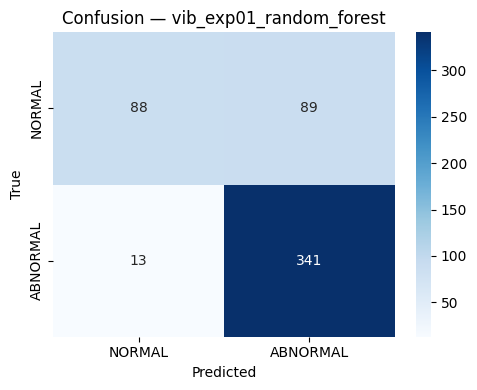

[SAVE] model → /content/drive/MyDrive/SAMS/models/vibration/vib_exp01_random_forest/model.joblib
[SAVE] metadata → /content/drive/MyDrive/SAMS/models/vibration/vib_exp01_random_forest/metadata.json
[SAVE] ledger → /content/drive/MyDrive/SAMS/results/vibration/vibration_experiment_ledger.csv
GC done.


In [17]:
exp_id = "vib_exp01_random_forest"
approach = "Classical baseline — Random Forest on window features"
print("EXPERIMENT:", exp_id)
print("APPROACH:  ", approach)

t0 = time.time()
rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_leaf=2,
    class_weight="balanced",
    n_jobs=-1,
    random_state=SEED,
)
rf.fit(X_train, y_train)

val_pred = rf.predict(X_val)
test_pred = rf.predict(X_test)
val_metrics = compute_metrics(y_val, val_pred)
test_metrics = compute_metrics(y_test, test_pred)
elapsed = time.time() - t0

print_metrics("VAL", val_metrics)
print_metrics("TEST", test_metrics)
print(f"Elapsed: {elapsed:.1f}s")

# Feature importance glance
imp = pd.Series(rf.feature_importances_, index=FEATURE_COLS).sort_values(ascending=False)
print("\nTop 10 features:")
print(imp.head(10))

save_experiment(
    exp_id, approach, rf, test_metrics,
    extra_meta={
        "model": "RandomForestClassifier",
        "elapsed_sec": elapsed,
        "val_f1_macro": val_metrics["f1_macro"],
        "top_features": imp.head(15).to_dict(),
        "hyperparams": {"n_estimators": 300, "class_weight": "balanced"},
    },
    kind="sklearn",
)
EXPERIMENT_RESULTS.append({"experiment_id": exp_id, "approach": approach, "test_metrics": test_metrics})

del rf
gc.collect()
print("GC done.")

### Experiment 2 — XGBoost (handcrafted features)

EXPERIMENT: vib_exp02_xgboost
APPROACH:   Boosted trees — XGBoost on window features

=== VAL ===
Accuracy:          0.8418
Precision (macro): 0.8220
Recall (macro):    0.8220
F1 (macro):        0.8220
F1 abnormal:       0.8814
              precision    recall  f1-score   support

      NORMAL     0.7627    0.7627    0.7627       177
    ABNORMAL     0.8814    0.8814    0.8814       354

    accuracy                         0.8418       531
   macro avg     0.8220    0.8220    0.8220       531
weighted avg     0.8418    0.8418    0.8418       531


=== TEST ===
Accuracy:          0.8644
Precision (macro): 0.8443
Recall (macro):    0.8630
F1 (macro):        0.8518
F1 abnormal:       0.8950
              precision    recall  f1-score   support

      NORMAL     0.7638    0.8588    0.8085       177
    ABNORMAL     0.9247    0.8672    0.8950       354

    accuracy                         0.8644       531
   macro avg     0.8443    0.8630    0.8518       531
weighted avg     0.8711    0.

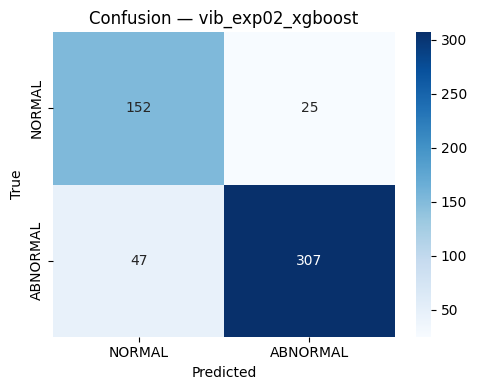

[SAVE] model → /content/drive/MyDrive/SAMS/models/vibration/vib_exp02_xgboost/model.joblib
[SAVE] metadata → /content/drive/MyDrive/SAMS/models/vibration/vib_exp02_xgboost/metadata.json
[SAVE] ledger → /content/drive/MyDrive/SAMS/results/vibration/vibration_experiment_ledger.csv
GC done.


In [18]:
from xgboost import XGBClassifier

exp_id = "vib_exp02_xgboost"
approach = "Boosted trees — XGBoost on window features"
print("EXPERIMENT:", exp_id)
print("APPROACH:  ", approach)

# Mild imbalance handling via scale_pos_weight
n_pos = max(1, int((y_train == 1).sum()))
n_neg = max(1, int((y_train == 0).sum()))
spw = n_neg / n_pos

t0 = time.time()
xgb = XGBClassifier(
    n_estimators=400,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.9,
    colsample_bytree=0.9,
    objective="binary:logistic",
    eval_metric="logloss",
    scale_pos_weight=spw,
    random_state=SEED,
    n_jobs=-1,
    tree_method="hist",
)
xgb.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    verbose=False,
)

val_pred = xgb.predict(X_val)
test_pred = xgb.predict(X_test)
val_metrics = compute_metrics(y_val, val_pred)
test_metrics = compute_metrics(y_test, test_pred)
elapsed = time.time() - t0

print_metrics("VAL", val_metrics)
print_metrics("TEST", test_metrics)
print(f"Elapsed: {elapsed:.1f}s | scale_pos_weight={spw:.3f}")

save_experiment(
    exp_id, approach, xgb, test_metrics,
    extra_meta={
        "model": "XGBClassifier",
        "elapsed_sec": elapsed,
        "val_f1_macro": val_metrics["f1_macro"],
        "scale_pos_weight": spw,
        "hyperparams": {"n_estimators": 400, "max_depth": 6, "learning_rate": 0.05},
    },
    kind="sklearn",
)
EXPERIMENT_RESULTS.append({"experiment_id": exp_id, "approach": approach, "test_metrics": test_metrics})

del xgb
gc.collect()
print("GC done.")

### Experiment 3 — SVM RBF (scaled handcrafted features)

EXPERIMENT: vib_exp03_svm_rbf
APPROACH:   Margin classifier — SVM RBF on scaled window features

=== VAL ===
Accuracy:          0.8832
Precision (macro): 0.8841
Recall (macro):    0.8489
F1 (macro):        0.8628
F1 abnormal:       0.9158
              precision    recall  f1-score   support

      NORMAL     0.8859    0.7458    0.8098       177
    ABNORMAL     0.8822    0.9520    0.9158       354

    accuracy                         0.8832       531
   macro avg     0.8841    0.8489    0.8628       531
weighted avg     0.8834    0.8832    0.8804       531


=== TEST ===
Accuracy:          0.8305
Precision (macro): 0.8210
Recall (macro):    0.7867
F1 (macro):        0.7994
F1 abnormal:       0.8784
              precision    recall  f1-score   support

      NORMAL     0.8000    0.6554    0.7205       177
    ABNORMAL     0.8420    0.9181    0.8784       354

    accuracy                         0.8305       531
   macro avg     0.8210    0.7867    0.7994       531
weighted avg     0

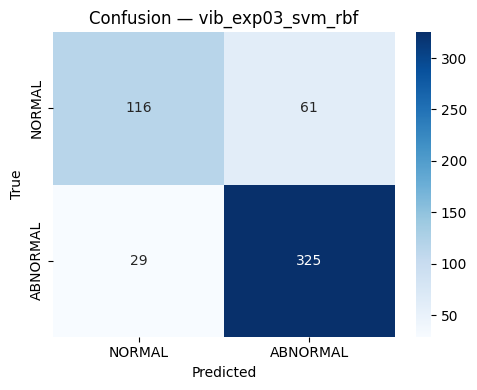

[SAVE] model → /content/drive/MyDrive/SAMS/models/vibration/vib_exp03_svm_rbf/model.joblib
[SAVE] metadata → /content/drive/MyDrive/SAMS/models/vibration/vib_exp03_svm_rbf/metadata.json
[SAVE] ledger → /content/drive/MyDrive/SAMS/results/vibration/vibration_experiment_ledger.csv
GC done.


In [19]:
exp_id = "vib_exp03_svm_rbf"
approach = "Margin classifier — SVM RBF on scaled window features"
print("EXPERIMENT:", exp_id)
print("APPROACH:  ", approach)

t0 = time.time()
svm = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", SVC(
        kernel="rbf",
        C=10.0,
        gamma="scale",
        class_weight="balanced",
        probability=False,
        random_state=SEED,
    )),
])
svm.fit(X_train, y_train)

val_pred = svm.predict(X_val)
test_pred = svm.predict(X_test)
val_metrics = compute_metrics(y_val, val_pred)
test_metrics = compute_metrics(y_test, test_pred)
elapsed = time.time() - t0

print_metrics("VAL", val_metrics)
print_metrics("TEST", test_metrics)
print(f"Elapsed: {elapsed:.1f}s")

save_experiment(
    exp_id, approach, svm, test_metrics,
    extra_meta={
        "model": "SVC(rbf)",
        "elapsed_sec": elapsed,
        "val_f1_macro": val_metrics["f1_macro"],
        "hyperparams": {"C": 10.0, "gamma": "scale", "class_weight": "balanced"},
    },
    kind="sklearn",
)
EXPERIMENT_RESULTS.append({"experiment_id": exp_id, "approach": approach, "test_metrics": test_metrics})

del svm
gc.collect()
print("GC done.")

### Experiment 4 — 1D CNN (raw X/Y/Z windows)

In [20]:
class Vib1DCNN(nn.Module):
    """Small 1D CNN over (channels=3, time=WINDOW_SIZE)."""

    def __init__(self, n_classes: int = 2):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv1d(3, 32, kernel_size=7, padding=3),
            nn.BatchNorm1d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool1d(2),
            nn.Conv1d(32, 64, kernel_size=5, padding=2),
            nn.BatchNorm1d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool1d(2),
            nn.Conv1d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm1d(128),
            nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool1d(1),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(128, n_classes),
        )

    def forward(self, x):
        # x: (B, T, 3) → (B, 3, T)
        x = x.transpose(1, 2)
        return self.classifier(self.features(x))


def make_loader(windows: np.ndarray, labels: np.ndarray, batch_size: int = 64, shuffle: bool = False):
    # Per-window z-score across time (stabilize scale across fan speeds)
    mu = windows.mean(axis=1, keepdims=True)
    sd = windows.std(axis=1, keepdims=True) + 1e-6
    normed = ((windows - mu) / sd).astype(np.float32)
    ds = TensorDataset(torch.from_numpy(normed), torch.from_numpy(labels.astype(np.int64)))
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle, num_workers=0)


@torch.no_grad()
def predict_loader(model: nn.Module, loader: DataLoader) -> Tuple[np.ndarray, np.ndarray]:
    model.eval()
    ys, ps = [], []
    for xb, yb in loader:
        xb = xb.to(device)
        logits = model(xb)
        pred = logits.argmax(dim=1).cpu().numpy()
        ys.append(yb.numpy())
        ps.append(pred)
    return np.concatenate(ys), np.concatenate(ps)


def train_cnn(
    epochs: int = 25,
    lr: float = 1e-3,
    batch_size: int = 64,
) -> Tuple[nn.Module, Dict[str, Any], Dict[str, list]]:
    train_loader = make_loader(W_train, y_train, batch_size=batch_size, shuffle=True)
    val_loader = make_loader(W_val, y_val, batch_size=batch_size, shuffle=False)
    test_loader = make_loader(W_test, y_test, batch_size=batch_size, shuffle=False)

    model = Vib1DCNN(n_classes=2).to(device)
    # Class weights from train counts
    counts = np.bincount(y_train, minlength=2).astype(np.float32)
    weights = counts.sum() / (2.0 * np.clip(counts, 1, None))
    criterion = nn.CrossEntropyLoss(weight=torch.tensor(weights, device=device))
    optim = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optim, mode="max", factor=0.5, patience=3)

    history = {"train_loss": [], "val_f1_macro": [], "val_accuracy": []}
    best_f1 = -1.0
    best_state = None

    for epoch in range(1, epochs + 1):
        model.train()
        losses = []
        pbar = tqdm(train_loader, desc=f"[1D-CNN] epoch {epoch}/{epochs}", leave=False)
        for xb, yb in pbar:
            xb, yb = xb.to(device), yb.to(device)
            optim.zero_grad(set_to_none=True)
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optim.step()
            losses.append(loss.item())
            pbar.set_postfix(loss=float(np.mean(losses)))

        yv, pv = predict_loader(model, val_loader)
        vm = compute_metrics(yv, pv)
        history["train_loss"].append(float(np.mean(losses)))
        history["val_f1_macro"].append(vm["f1_macro"])
        history["val_accuracy"].append(vm["accuracy"])
        scheduler.step(vm["f1_macro"])

        print(
            f"  epoch {epoch:02d} | train_loss={history['train_loss'][-1]:.4f} "
            f"| val_acc={vm['accuracy']:.4f} | val_f1_macro={vm['f1_macro']:.4f}"
        )
        if vm["f1_macro"] > best_f1:
            best_f1 = vm["f1_macro"]
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

    if best_state is not None:
        model.load_state_dict(best_state)

    yt, pt = predict_loader(model, test_loader)
    test_metrics = compute_metrics(yt, pt)
    return model, test_metrics, history


print("1D CNN helpers ready.")

1D CNN helpers ready.


EXPERIMENT: vib_exp04_1dcnn
APPROACH:   Deep learning — 1D CNN on raw X/Y/Z windows


[1D-CNN] epoch 1/25:   0%|          | 0/31 [00:00<?, ?it/s]

  epoch 01 | train_loss=0.3333 | val_acc=0.6949 | val_f1_macro=0.6914


[1D-CNN] epoch 2/25:   0%|          | 0/31 [00:00<?, ?it/s]

  epoch 02 | train_loss=0.0838 | val_acc=0.7024 | val_f1_macro=0.6946


...

  epoch 23 | train_loss=0.0015 | val_acc=0.7458 | val_f1_macro=0.7167


[1D-CNN] epoch 24/25:   0%|          | 0/31 [00:00<?, ?it/s]

  epoch 24 | train_loss=0.0018 | val_acc=0.7401 | val_f1_macro=0.6966


[1D-CNN] epoch 25/25:   0%|          | 0/31 [00:00<?, ?it/s]

  epoch 25 | train_loss=0.0017 | val_acc=0.7345 | val_f1_macro=0.6916

=== TEST ===
Accuracy:          0.7571
Precision (macro): 0.7655
Recall (macro):    0.7980
F1 (macro):        0.7520
F1 abnormal:       0.7875
              precision    recall  f1-score   support

      NORMAL     0.5863    0.9209    0.7165       177
    ABNORMAL     0.9447    0.6751    0.7875       354

    accuracy                         0.7571       531
   macro avg     0.7655    0.7980    0.7520       531
weighted avg     0.8252    0.7571    0.7638       531

Elapsed: 16.4s | best_val_f1≈0.7323


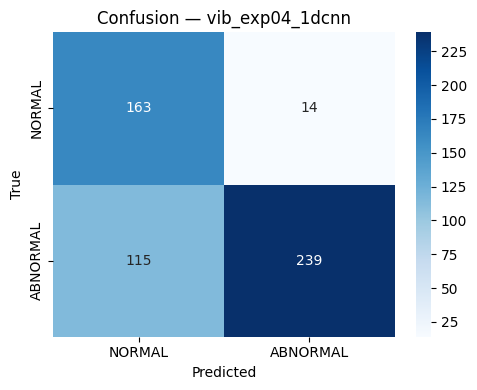

[SAVE] model → /content/drive/MyDrive/SAMS/models/vibration/vib_exp04_1dcnn/model.pt
[SAVE] metadata → /content/drive/MyDrive/SAMS/models/vibration/vib_exp04_1dcnn/metadata.json
[SAVE] ledger → /content/drive/MyDrive/SAMS/results/vibration/vibration_experiment_ledger.csv


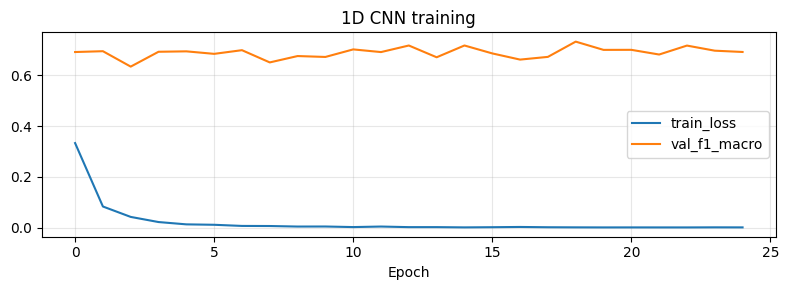

GC done.


In [21]:
exp_id = "vib_exp04_1dcnn"
approach = "Deep learning — 1D CNN on raw X/Y/Z windows"
print("EXPERIMENT:", exp_id)
print("APPROACH:  ", approach)

t0 = time.time()
cnn_model, test_metrics, history = train_cnn(epochs=25, lr=1e-3, batch_size=64)
elapsed = time.time() - t0

print_metrics("TEST", test_metrics)
print(f"Elapsed: {elapsed:.1f}s | best_val_f1≈{max(history['val_f1_macro']):.4f}")

# Save weights dict + small architecture note
payload = {
    "model_state_dict": cnn_model.state_dict(),
    "architecture": "Vib1DCNN",
    "input": "(batch, window=100, channels=3)",
    "class_names": CLASS_NAMES,
    "history": history,
}
save_experiment(
    exp_id, approach, payload, test_metrics,
    extra_meta={
        "model": "Vib1DCNN",
        "elapsed_sec": elapsed,
        "epochs": 25,
        "best_val_f1_macro": float(max(history["val_f1_macro"])),
        "device": str(device),
    },
    kind="torch",
)
EXPERIMENT_RESULTS.append({"experiment_id": exp_id, "approach": approach, "test_metrics": test_metrics})

# Persist history plot
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(history["train_loss"], label="train_loss")
ax.plot(history["val_f1_macro"], label="val_f1_macro")
ax.set_xlabel("Epoch")
ax.legend()
ax.set_title("1D CNN training")
ax.grid(alpha=0.3)
plt.tight_layout()
hist_path = MODELS_DIR / exp_id / "training_curves.png"
plt.savefig(hist_path, dpi=140)
plt.show()

del cnn_model
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
print("GC done.")

## 6. Comparison — pick the SAMS vibration backbone

In [22]:
ledger_path = RESULTS_DIR / "vibration_experiment_ledger.csv"
if ledger_path.exists():
    comparison_df = pd.read_csv(ledger_path)
else:
    comparison_df = pd.DataFrame([
        {
            "experiment_id": r["experiment_id"],
            "approach": r["approach"],
            "accuracy": r["test_metrics"]["accuracy"],
            "precision_macro": r["test_metrics"]["precision_macro"],
            "recall_macro": r["test_metrics"]["recall_macro"],
            "f1_macro": r["test_metrics"]["f1_macro"],
            "f1_weighted": r["test_metrics"]["f1_weighted"],
            "f1_abnormal": r["test_metrics"]["f1_abnormal"],
        }
        for r in EXPERIMENT_RESULTS
    ])

comparison_df = comparison_df.sort_values("f1_macro", ascending=False).reset_index(drop=True)
comparison_path = RESULTS_DIR / "vibration_comparison.csv"
comparison_df.to_csv(comparison_path, index=False)

print("=== SAMS Vibration Model Comparison (sorted by F1-macro) ===")
display_cols = [
    "experiment_id", "approach", "accuracy",
    "precision_macro", "recall_macro", "f1_macro", "f1_weighted", "f1_abnormal",
]
cols = [c for c in display_cols if c in comparison_df.columns]
print(comparison_df[cols].to_string(index=False))
print("\nSaved:", comparison_path)

best = comparison_df.iloc[0]
print("\n★ Best experiment:", best["experiment_id"])
print("  Approach:", best["approach"])
print("  Accuracy:", round(float(best["accuracy"]), 4))
print("  F1-macro:", round(float(best["f1_macro"]), 4))

=== SAMS Vibration Model Comparison (sorted by F1-macro) ===
          experiment_id                                              approach  accuracy  precision_macro  recall_macro  f1_macro  f1_weighted  f1_abnormal
      vib_exp02_xgboost            Boosted trees — XGBoost on window features  0.864407         0.844259      0.862994  0.851777     0.866199     0.895044
      vib_exp03_svm_rbf Margin classifier — SVM RBF on scaled window features  0.830508         0.820984      0.786723  0.799438     0.825751     0.878378
        vib_exp04_1dcnn           Deep learning — 1D CNN on raw X/Y/Z windows  0.757062         0.765497      0.798023  0.751981     0.763814     0.787479
vib_exp01_random_forest Classical baseline — Random Forest on window features  0.807910         0.832155      0.730226  0.751496     0.790963     0.869898

Saved: /content/drive/MyDrive/SAMS/results/vibration/vibration_comparison.csv

★ Best experiment: vib_exp02_xgboost
  Approach: Boosted trees — XGBoost on window f

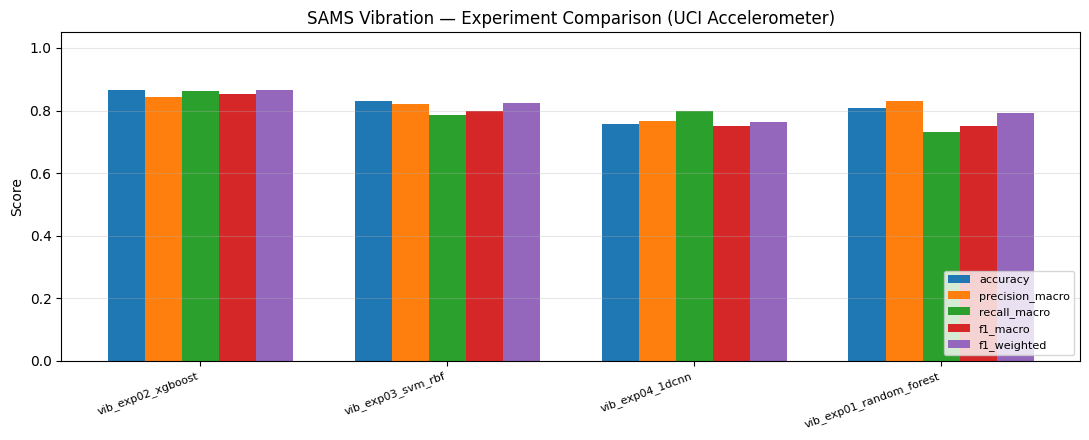

Saved chart: /content/drive/MyDrive/SAMS/results/vibration/vibration_comparison_bars.png


In [23]:
plot_df = comparison_df.copy()
metrics = [c for c in ["accuracy", "precision_macro", "recall_macro", "f1_macro", "f1_weighted"] if c in plot_df.columns]

fig, ax = plt.subplots(figsize=(11, 4.5))
x = np.arange(len(plot_df))
width = 0.15
for i, m in enumerate(metrics):
    ax.bar(x + i * width, plot_df[m], width, label=m)
ax.set_xticks(x + width * (len(metrics) - 1) / 2)
ax.set_xticklabels(plot_df["experiment_id"], rotation=20, ha="right", fontsize=8)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score")
ax.set_title("SAMS Vibration — Experiment Comparison (UCI Accelerometer)")
ax.legend(fontsize=8, loc="lower right")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
fig_path = RESULTS_DIR / "vibration_comparison_bars.png"
plt.savefig(fig_path, dpi=150)
plt.show()
print("Saved chart:", fig_path)

In [24]:
summary = {
    "task": "vibration_normal_abnormal",
    "dataset": "UCI Accelerometer (id=846)",
    "num_experiments": int(len(comparison_df)),
    "primary_metric": "f1_macro",
    "best_experiment_id": str(best["experiment_id"]),
    "best_approach": str(best["approach"]),
    "best_metrics": {
        "accuracy": float(best["accuracy"]),
        "precision_macro": float(best["precision_macro"]),
        "recall_macro": float(best["recall_macro"]),
        "f1_macro": float(best["f1_macro"]),
        "f1_weighted": float(best["f1_weighted"]),
    },
    "label_map": {"wconfid=1": "NORMAL", "wconfid=2|3": "ABNORMAL"},
    "window": {"size": WINDOW_SIZE, "stride": WINDOW_STRIDE, "sample_rate_hz": SAMPLE_RATE_HZ},
    "models_dir": str(MODELS_DIR),
    "generated_at_utc": datetime.now(timezone.utc).isoformat(),
}
summary_path = RESULTS_DIR / "vibration_comparison_summary.json"
with open(summary_path, "w") as f:
    json.dump(summary, f, indent=2)
print("Summary:", summary_path)
print(json.dumps(summary["best_metrics"], indent=2))

Summary: /content/drive/MyDrive/SAMS/results/vibration/vibration_comparison_summary.json
{
  "accuracy": 0.864406779661017,
  "precision_macro": 0.8442589453290549,
  "recall_macro": 0.8629943502824858,
  "f1_macro": 0.851777185038149,
  "f1_weighted": 0.8661993672849079
}


In [25]:
print("Done. Vibration (UCI) experiment suite finished.")
print("Models:", MODELS_DIR)
print("Results:", RESULTS_DIR)

Done. Vibration (UCI) experiment suite finished.
Models: /content/drive/MyDrive/SAMS/models/vibration
Results: /content/drive/MyDrive/SAMS/results/vibration
